# HW2 – 1. Data understanding and preprocessing (VisDrone)

## 1. Setup

In [18]:
# Make the repo importable: Kaggle clones it, locally the root is the parent of notebooks/
import os, sys
from pathlib import Path
if os.path.exists("/kaggle/working"):
    if not os.path.exists("/kaggle/working/repo"):
        !git clone --depth 1 https://github.com/BohdanZasymovych/ai-hw2-object-detection.git /kaggle/working/repo
    !pip install -q pycocotools huggingface_hub   # only if missing; torch/torchvision stay Kaggle's own CUDA builds
    ROOT_DIR = Path("/kaggle/working/repo")
else:
    ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT_DIR))

In [19]:
# Live reload of utils/common.py when editing locally (Kaggle's IPython autoreload is broken on Python 3.13)
if not os.path.exists("/kaggle/working"):
    %load_ext autoreload
    %autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.common import *

seed_everything()
download_data()
print(env_info(), "| data:", RAW_DIR)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Using dataset in /home/bohdan/code/ai/hw2-object-detection/data/raw
{'python': '3.14.4', 'torch': '2.15.0+cu132', 'torchvision': '0.29.2+cu132', 'gpu': 'NVIDIA GeForce RTX 2050', 'on_kaggle': False} | data: /home/bohdan/code/ai/hw2-object-detection/data/raw


In [20]:
# Quick look at the dataset layout
for p in sorted(RAW_DIR.iterdir()):
    n = sum(1 for _ in p.rglob("*")) if p.is_dir() else 1
    print(f"{p.name:40s} {'dir ' if p.is_dir() else 'file'} {n} entries")

test                                     dir  3860 entries
test_images.csv                          file 1 entries
train                                    dir  66659 entries
val                                      dir  7150 entries


## 2. Data understanding & preprocessing

Goal: understand the data before modelling and fix the preprocessing protocol. The dataset (JSON `info`: "VisDrone, 8-class merged labels") consists of video sequences with box annotations for 8 classes, given as COCO JSON (`annotations_coco.json`) and YOLO txt labels (`labels/`, `ignore/`).

### 2.1 Dataset overview

In [21]:
# Clean per-split tables from the shared loader (frames, real boxes, ignore regions)
imgs, boxes, ignore = {}, {}, {}
for s in ["train", "val"]:
    imgs[s], boxes[s], ignore[s] = load_split(s)
test = pd.read_csv(RAW_DIR / "test_images.csv")

rows = []
for s in ["train", "val"]:
    rows.append({"split": s, "sequences": imgs[s].seq.nunique(), "frames": len(imgs[s]),
                 "boxes": len(boxes[s])})
rows.append({"split": "test", "sequences": test["clip"].nunique(), "frames": len(test), "boxes": "hidden"})
pd.DataFrame(rows).set_index("split")

,sequences,frames,boxes
split,,,
train,56,24201,1105516
val,7,2846,114132
test,48,3811,hidden


In [22]:
frames = {"train": imgs["train"], "val": imgs["val"], "test": test}
res = pd.DataFrame({s: (f["width"].astype(str) + "x" + f["height"].astype(str)).value_counts() for s, f in frames.items()})
res = res.fillna(0).astype(int)
res = res.loc[sorted(res.index, key=lambda r: tuple(map(int, r.split("x"))))]
pd.concat({"frames": res, "% of split": (res / res.sum() * 100).round(1)}, axis=1)

frames            % of split            
           train  val  test      train   val  test
680x382        0    0   321        0.0   0.0   8.4
960x540        0    0   279        0.0   0.0   7.3
1344x756    5645  827   441       23.3  29.1  11.6
1360x764       0    0  1474        0.0   0.0  38.7
1360x765     962    0     0        4.0   0.0   0.0
1904x1071  12895  459     0       53.3  16.1   0.0
1904x1072      0    0   305        0.0   0.0   8.0
1920x1080    721    0   991        3.0   0.0  26.0
2688x1512   3505  233     0       14.5   8.2   0.0
2720x1530    473  349     0        2.0  12.3   0.0
3840x2160      0  978     0        0.0  34.4   0.0

In [23]:
# Split sanity: train and val must not share any sequence (frames of one video are highly correlated)
overlap = set(imgs["train"].seq) & set(imgs["val"].seq)
print("Shared train/val sequences:", overlap or "none")

Shared train/val sequences: none


**Findings.** The provided train/val split is already by sequence (no shared videos): 56 train / 7 val sequences, 24k / 2.8k frames, 1.1M / 114k boxes. The val set is small (7 videos), so its metrics are noisy.

Frames come in a few fixed resolutions, and the mix differs between splits: train is mostly 1904x1071 (53%), val has 34% 4K frames (3840x2160), and test has no frames wider than 1920 px but 16% low-resolution ones (680x382, 960x540) that do not occur in train or val.

### 2.2 Annotation format and ignore regions

In [24]:
# Cross-check the COCO json against the YOLO txt labels: the counts must be equal
rows = []
for s in ["train", "val"]:
    rows.append({"split": s,
                 "boxes, json": len(boxes[s]),
                 "boxes, txt": sum(sum(1 for _ in open(f)) for f in (RAW_DIR / s / "labels").rglob("*.txt")),
                 "ignore regions, json": len(ignore[s]),
                 "ignore regions, txt": sum(sum(1 for _ in open(f)) for f in (RAW_DIR / s / "ignore").rglob("*.txt"))})
pd.DataFrame(rows).set_index("split")

,"boxes, json","boxes, txt","ignore regions, json","ignore regions, txt"
split,,,,
train,1105516,1105516,63843,63843
val,114132,114132,3995,3995


In [25]:
# Original VisDrone ids merged into each class, and the ignore regions (train)
bt, it = boxes["train"], ignore["train"]
merged = bt.groupby("cls").orig_category_id.agg(lambda s: ", ".join(map(str, sorted(s.astype(int).unique()))))
display(merged.reindex(CLASSES).rename("merged original ids").to_frame())
display(it.orig_category_id.astype(int).value_counts().rename("ignore regions").rename_axis("original id").to_frame())

# are the ignore regions free of boxes? share of boxes whose centre lies inside an ignore region of the same frame
groups, inside = it.groupby("image_id"), 0
for iid, g in bt[bt.image_id.isin(it.image_id)].groupby("image_id"):
    r = groups.get_group(iid)
    cx, cy = (g.x + g.w / 2).to_numpy()[:, None], (g.y + g.h / 2).to_numpy()[:, None]
    inside += int(((r.x.to_numpy() <= cx) & (cx <= (r.x + r.w).to_numpy()) & (r.y.to_numpy() <= cy) & (cy <= (r.y + r.h).to_numpy())).any(1).sum())
pd.DataFrame({"value": [f"{it.image_id.nunique() / len(imgs['train']) * 100:.0f}%", f"{(it.w * it.h).pow(.5).median():.0f} px",
                        f"{bt['size'].median():.0f} px", f"{inside / len(bt) * 100:.1f}%"]},
             index=["frames with an ignore region", "median size sqrt(w*h), ignore region", "median size sqrt(w*h), real box",
                    "real boxes with centre inside an ignore region"]).rename_axis("ignore regions (train)")

,merged original ids
cls,
person,"1, 2"
bicycle,3
car,4
van,5
truck,6
tricycle,"7, 8"
bus,9
motor,10


,ignore regions
original id,
0,62369
11,1474


,value
ignore regions (train),
frames with an ignore region,75%
"median size sqrt(w*h), ignore region",94 px
"median size sqrt(w*h), real box",46 px
real boxes with centre inside an ignore region,1.1%


**Handling.** Besides the 8 classes, the JSON holds entries with `iscrowd=1` and `ignore=1` whose `orig_category_id` is 0 or 11; the YOLO labels keep them in the separate `ignore/` folder. We call them **ignore regions**; the data does not say what ids 0 and 11 mean, so both are treated the same way. Each region is stored once per class (8 copies) and deduplicated for statistics. The JSON and YOLO labels match box-for-box. Rules:
- **Training:** only `iscrowd=0` boxes (8 classes; `orig_category_id` shows original ids 1 and 2 merged into `person`, 7 and 8 into `tricycle`). Ignore regions are not targets.
- **Evaluation:** keep `iscrowd=1` entries so `pycocotools` skips detections inside them.

In [26]:
# Quality checks on the training boxes
b = boxes["train"]
pd.DataFrame({"value": [int(((b.w < 2) | (b.h < 2)).sum()), f"{(b.truncation > 0).mean() * 100:.0f}%"]},
             index=["degenerate boxes (w or h < 2 px)", "boxes with truncation flag set"]).rename_axis("check (train)")

,value
check (train),
degenerate boxes (w or h < 2 px),0
boxes with truncation flag set,4%


### 2.3 Sample frames (conversion check)

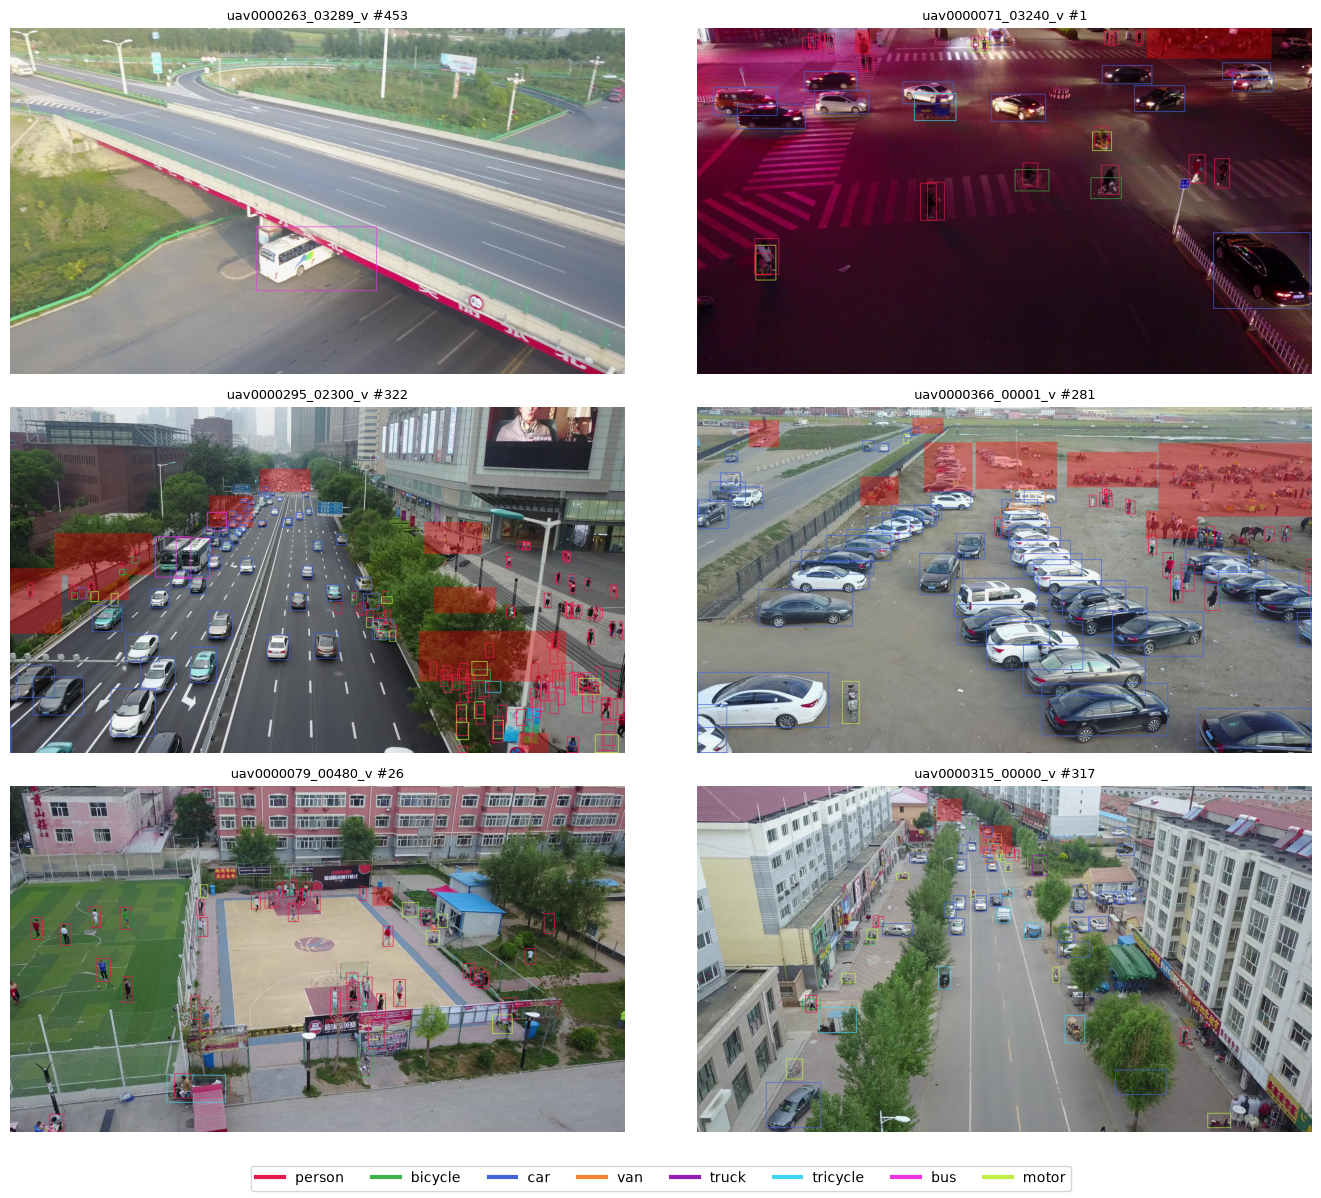

In [27]:
# GT boxes (coloured by class) and ignore regions (red) with the shared draw_frame:
# sparsest, median and densest frame, a random frame with ignore regions, and two random frames from other sequences
per_frame = boxes["train"].groupby("image_id").size()
ign_ids = set(ignore["train"].image_id)
picks = [per_frame.idxmin(), per_frame.sub(per_frame.median()).abs().idxmin(), per_frame.idxmax()]
picks.append(next(i for i in per_frame.sample(frac=1, random_state=SEED).index if i in ign_ids and i not in picks))
seq_of = imgs["train"].set_index("image_id").seq
used = set(seq_of[picks])
for i in per_frame.sample(frac=1, random_state=SEED + 1).index:
    if seq_of[i] not in used:
        picks.append(i); used.add(seq_of[i])
    if len(picks) == 6:
        break
fig, axs = plt.subplots(3, 2, figsize=(14, 12))
for ax, i in zip(axs.ravel(), picks):
    draw_frame("train", i, ax)
fig.legend(handles=[plt.Line2D([], [], color=c, lw=3, label=n) for c, n in zip(COLORS, CLASSES)], loc="lower center", ncol=8)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

In [28]:
# One of the frames looks wrong (many boxes without an object): compare its box count with the neighbouring frames of its sequence
def frame_counts(split):
    c = boxes[split].merge(imgs[split][["image_id", "frame_id"]], on="image_id").groupby(["seq", "frame_id"]).size().rename("n").reset_index()
    c = c.sort_values(["seq", "frame_id"])
    c["prev"], c["next"] = c.groupby("seq").n.shift(1), c.groupby("seq").n.shift(-1)
    return c, c[(c.n > 1.3 * c.prev + 15) & (c.n > 1.3 * c.next + 15)]       # far more boxes than both neighbours


for split in ["train", "val"]:
    counts, spike = frame_counts(split)
    print(f"{split}: frames with far more boxes than both neighbours: {len(spike)} of {len(counts)}")
    if len(spike):
        display(spike.set_index(["seq", "frame_id"]))

# in the spike frame: boxes whose track is absent from both neighbouring frames, and how closely they repeat a box of the same track elsewhere
_, spike = frame_counts("train")
s = spike.iloc[0]
b = boxes["train"].merge(imgs["train"][["image_id", "frame_id"]], on="image_id")
b = b[b.seq == s.seq]
present = set(zip(b.track_id, b.frame_id))
cur = b[b.frame_id == s.frame_id]
iso = cur[[((t, s.frame_id - 1) not in present) and ((t, s.frame_id + 1) not in present) for t in cur.track_id]]


def best_iou(r):
    o = b[(b.track_id == r.track_id) & (b.frame_id != s.frame_id)]
    ix = (np.minimum(o.x + o.w, r.x + r.w) - np.maximum(o.x, r.x)).clip(lower=0)
    iy = (np.minimum(o.y + o.h, r.y + r.h) - np.maximum(o.y, r.y)).clip(lower=0)
    return (ix * iy / (o.w * o.h + r.w * r.h - ix * iy)).max()


pd.DataFrame({"value": [len(cur), int(s.prev), int(s.next), len(iso), f"{np.median([best_iou(r) for r in iso.itertuples()]):.2f}"]},
             index=["boxes in the frame", "boxes in previous frame", "boxes in next frame", "boxes whose track is absent from both neighbours",
                    "median IoU with the same track elsewhere"]).rename_axis(f"{s.seq} #{int(s.frame_id)}")

train: frames with far more boxes than both neighbours: 1 of 24198


,,n,prev,next
seq,frame_id,,,
uav0000295_02300_v,322,180,100.0,88.0


val: frames with far more boxes than both neighbours: 0 of 2846


,value
uav0000295_02300_v #322,
boxes in the frame,180
boxes in previous frame,100
boxes in next frame,88
boxes whose track is absent from both neighbours,82
median IoU with the same track elsewhere,1.00


**Findings.** Most boxes line up with the objects, so the conversion is correct. Ignore regions (red) are larger than a typical box and mostly free of boxes (see 2.2: only about 1% of boxes lie inside one, while three quarters of the frames have at least one). Objects are small relative to the frame and often densely packed.

**Possibly incorrect labels.** One of the six frames, `uav0000295_02300_v` #322, stands out: it has 180 boxes, its neighbouring frames 100 and 88. 82 of its boxes belong to tracks missing from both neighbouring frames and repeat earlier boxes of the same tracks; the ones we inspected have no visible object under them (empty road, foliage). We saw no such problem in the other five frames, and the check above finds no other such frame in train or val. The check only detects unusual box counts, so it cannot find other kinds of incorrect labels or tell how many there are. If more frames have incorrect labels, they add false targets in training and count correct detections as errors in evaluation.

### 2.4 Class distribution

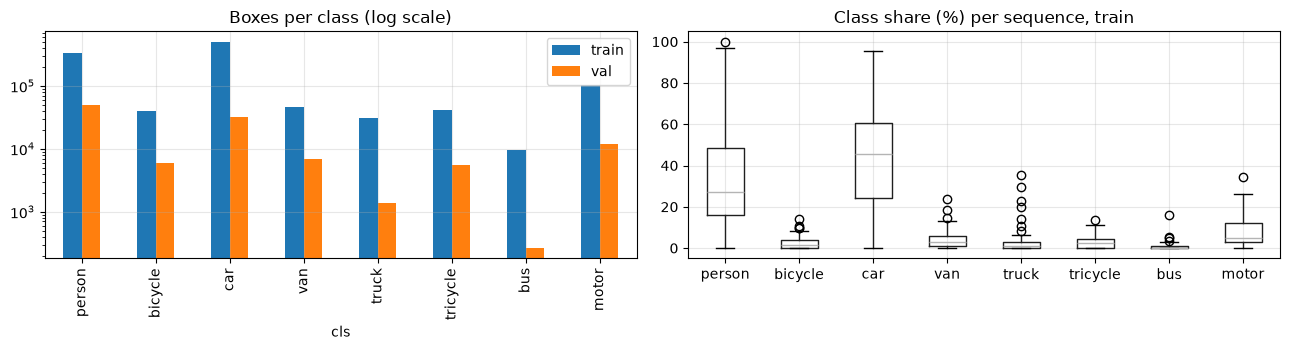

,train,val,train %,val %,train sequences without class
cls,,,,,
person,328701,50312,29.7,44.1,1
bicycle,40255,6022,3.6,5.3,15
car,505301,31821,45.7,27.9,7
van,46940,6842,4.2,6.0,10
truck,30498,1359,2.8,1.2,17
tricycle,41349,5487,3.7,4.8,17
bus,9653,264,0.9,0.2,32
motor,102819,12025,9.3,10.5,6


In [29]:
cnt = pd.DataFrame({s: boxes[s].cls.value_counts() for s in boxes}).reindex(CLASSES)
share = (cnt / cnt.sum() * 100).round(1)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
cnt.plot.bar(ax=axs[0], logy=True, title="Boxes per class (log scale)")

# Per-sequence class mix: does the dominant class differ between videos?
mix = boxes["train"].groupby(["seq", "cls"]).size().unstack(fill_value=0).reindex(columns=CLASSES)
(mix.div(mix.sum(axis=1), axis=0) * 100).boxplot(ax=axs[1]); axs[1].set_title("Class share (%) per sequence, train")
plt.tight_layout(); plt.show()

tab = pd.concat([cnt, share.add_suffix(" %")], axis=1)
tab["train sequences without class"] = (mix == 0).sum()
tab

**Findings.** Strong imbalance: car (46%) and person (30%) dominate, `bus` is under 1% and `bicycle` and `tricycle` are about 4% each and `truck` 3%. Class mix is sequence-specific (e.g. no bus in 32 of 56 sequences), and val has a different mix from train (more person, fewer car, only 264 buses), so per-class AP on val, especially bus, will be noisy.

### 2.5 Object size

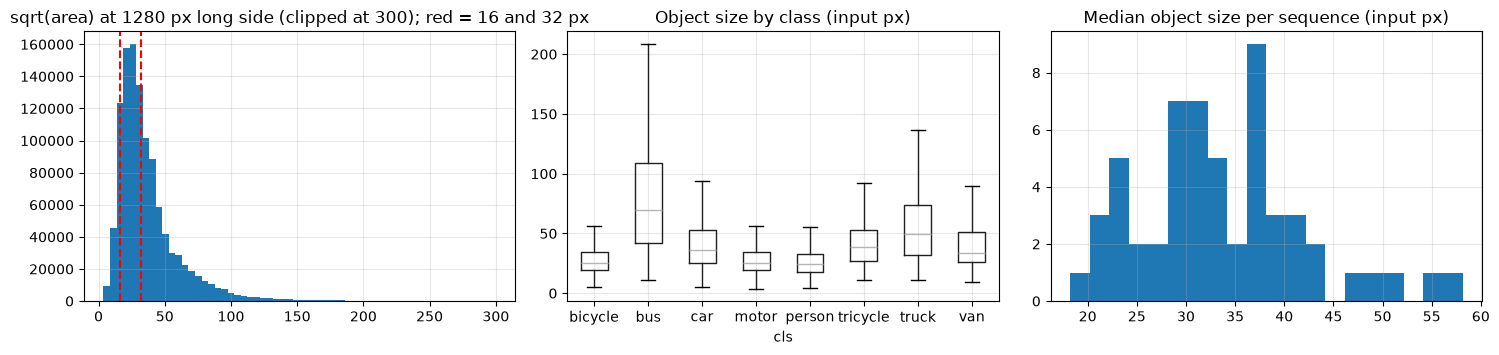

,% of boxes
COCO bucket at 1280 px,
small,54.2
medium,42.8
large,3.0


size_in,small,medium,large
class (% of its boxes),,,
person,73.0,27.0,0.0
bicycle,70.0,30.0,0.0
car,42.0,53.0,4.0
van,44.0,51.0,5.0
truck,26.0,59.0,14.0
tricycle,36.0,60.0,4.0
bus,13.0,55.0,32.0
motor,70.0,29.0,0.0


,boxes,median_native_px,median_input_px,small_pct
native resolution,,,,
1344x756,155031,33.0,31.4,52.1
1360x765,52919,31.5,29.6,55.2
1904x1071,593183,47.7,32.1,49.8
1920x1080,40928,38.2,25.5,67.5
2688x1512,230795,54.2,25.8,63.2
2720x1530,32660,58.1,27.3,62.2


,"median object size per sequence, input px"
min,18.2
median,32.3
max,58.1


,% boxes < 16 px
"input long side, px",
640,54.2
960,24.0
1280,9.8
1920,1.7


In [30]:
bt = boxes["train"].copy()
# Size as it will be seen by the model: sqrt(area) after resizing the long side to INPUT_LONG (same as the protocol in 1.2).
# Pixel sizes in the native frames depend on each frame's resolution, so they are not comparable across sequences.
INPUT_LONG = 1280
bt["size_in"] = bt["size"] * INPUT_LONG / bt[["width", "height"]].max(axis=1)
bt["res"] = bt.width.astype(int).astype(str) + "x" + bt.height.astype(int).astype(str)
SMALL, MEDIUM = 32, 96   # COCO thresholds, applied at the input size
bt_size = pd.cut(bt["size_in"], [0, SMALL, MEDIUM, 1e9], labels=["small", "medium", "large"])
seq_size = bt.groupby("seq")["size_in"].median()

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
axs[0].hist(bt["size_in"].clip(upper=300), bins=60); axs[0].axvline(16, c="r", ls="--"); axs[0].axvline(32, c="r", ls="--")
axs[0].set_title(f"sqrt(area) at {INPUT_LONG} px long side (clipped at 300); red = 16 and 32 px")
bt.boxplot(column="size_in", by="cls", ax=axs[1], showfliers=False); axs[1].set_title("Object size by class (input px)"); plt.suptitle("")
axs[2].hist(seq_size, bins=20); axs[2].set_title("Median object size per sequence (input px)")
plt.tight_layout(); plt.show()

size_tab = (bt_size.value_counts(normalize=True) * 100).round(1).rename("% of boxes").rename_axis(f"COCO bucket at {INPUT_LONG} px").to_frame()
class_size = pd.crosstab(bt.cls, bt_size, normalize="index").mul(100).round(0).reindex(CLASSES)
class_size.index.name = "class (% of its boxes)"
res_size = bt.assign(b=bt_size).groupby("res").agg(
    boxes=("size_in", "size"), median_native_px=("size", "median"), median_input_px=("size_in", "median"),
    small_pct=("b", lambda s: (s == "small").mean() * 100)).round(1)
res_size = res_size[res_size.boxes > 5000]
res_size.index.name = "native resolution"
seq_tab = seq_size.describe()[["min", "50%", "max"]].round(1).rename({"50%": "median"}).rename("median object size per sequence, input px").to_frame()

# How many boxes would be under 16 px for other input sizes (the 1280 px choice in 2.8)
eff = pd.DataFrame({L: (bt["size"] * L / bt[["width", "height"]].max(axis=1) < 16).mean() * 100 for L in [640, 960, 1280, 1920]},
                   index=["% boxes < 16 px"]).round(1).T.rename_axis("input long side, px")
for t in (size_tab, class_size, res_size, seq_tab, eff):
    display(t)

In [31]:
# Box-shape clusters (k-means on relative w,h, 1-IoU distance as in YOLOv2) -> anchor config
def iou_wh(wh, c):
    inter = np.minimum(wh[:, None, 0], c[None, :, 0]) * np.minimum(wh[:, None, 1], c[None, :, 1])
    return inter / (wh[:, 0:1] * wh[:, 1:2] + (c[:, 0] * c[:, 1])[None] - inter)


def kmeans_anchors(wh, k, iters=50, seed=SEED):
    rng = np.random.default_rng(seed)
    c = wh[rng.choice(len(wh), k, replace=False)]
    for _ in range(iters):
        a = iou_wh(wh, c).argmax(1)
        c = np.array([np.median(wh[a == j], axis=0) if (a == j).any() else c[j] for j in range(k)])
    return c[np.argsort(c[:, 0] * c[:, 1])], iou_wh(wh, c).max(1).mean()


wh = bt[["rel_w", "rel_h"]].sample(200_000, random_state=SEED).to_numpy()
INPUT_LONG = 1280   # candidate long-side input resolution (see 2.8)
rows = []
for k in [3, 5, 9]:
    c, miou = kmeans_anchors(wh, k)
    px = (c * [INPUT_LONG, INPUT_LONG * 9 / 16]).round(0).astype(int)
    row = {"k": k, "mean best IoU": round(miou, 2)}
    row.update({f"anchor {j + 1}": f"{p[0]}x{p[1]}" for j, p in enumerate(px)})   # one column per anchor, w x h at 1280 px
    rows.append(row)
anchor_tab = pd.DataFrame(rows).set_index("k")
anchor_tab.index.name = f"k (anchors at {INPUT_LONG} px, w x h)"
ratio = (bt.h / bt.w).quantile([.1, .5, .9]).round(2).rename("h / w").rename_axis("percentile").to_frame()
display(anchor_tab)
display(ratio)

,mean best IoU,anchor 1,anchor 2,anchor 3,anchor 4,anchor 5,anchor 6,anchor 7,anchor 8,anchor 9
"k (anchors at 1280 px, w x h)",,,,,,,,,,
3,0.60,15x21,32x32,75x58,NaN,NaN,NaN,NaN,NaN,NaN
5,0.66,13x18,19x34,32x23,44x41,92x66,NaN,NaN,NaN,NaN
9,0.73,11x15,13x28,22x19,20x39,40x22,30x31,39x53,63x34,100x72


,h / w
percentile,
0.1,0.47
0.5,1.06
0.9,2.25


**Findings.** Sizes are measured at the 1280 px input, because native pixel sizes depend on each frame's resolution. At the input size, 54% of boxes are COCO-small (<32 px), 43% medium and 3% large; person, bicycle and motor are mostly small, bus mostly large. Sizes are similar across resolution groups (50–68% small), and the median size per sequence ranges from 18 to 58 px, so the scale varies less than the native sizes suggested. Downscaling still hurts: at a 640 px long side 54% of boxes would be under 16 px, at 1280 px it is 10%, at 1920 px under 2%. **We use a 1280 px long side**. Box shapes are mostly near-square to tall (h/w 0.47–2.25 for the 10th–90th percentile), so anchor aspect ratios {0.5, 1, 2} cover them. The k-means anchors at 1280 px are about 13–100 px, so anchor sizes should start at about 13 px (not the 32 px framework default) and use a high-resolution (stride 4 or 8) level. 99% of boxes are under 130 px. Notebook 02 uses one size per FPN level from a 1D k-means (log scale) of the box sizes: 13/21/31/48/87 px.

### 2.6 Scene density

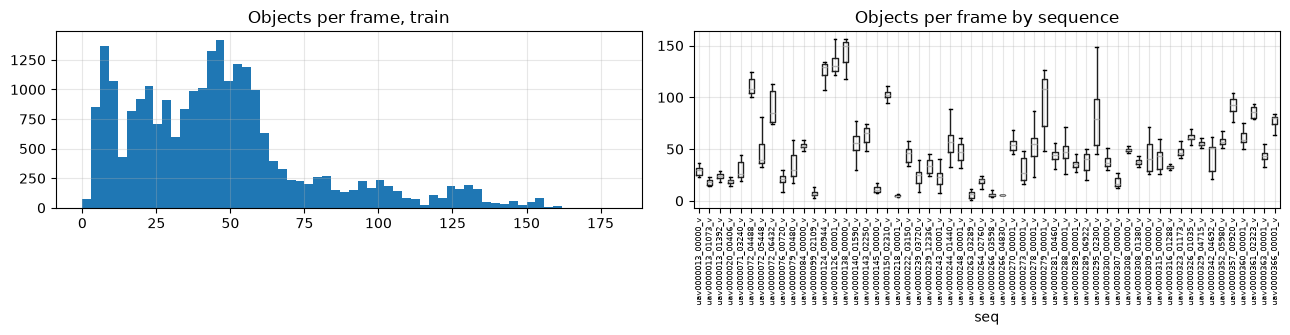

,train,val
density,,
mean objects per frame,45.7,40.1
median,43,37
95th percentile,118,103
max,180,116
mean per sequence (min to max),5.1 to 143.0,-
frames with 0 objects,0.0%,0.0%
frames with > 100 objects,7.6%,6.4%


In [32]:
dens = {s: boxes[s].groupby("image_id").size().reindex(imgs[s].image_id, fill_value=0) for s in boxes}
dens_seq = imgs["train"].assign(n=dens["train"].values).groupby("seq").n.agg(["mean", "max"]).round(1)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
axs[0].hist(dens["train"], bins=60); axs[0].set_title("Objects per frame, train")
imgs["train"].assign(n=dens["train"].values).boxplot(column="n", by="seq", ax=axs[1], showfliers=False)
axs[1].set_title("Objects per frame by sequence"); axs[1].tick_params(axis="x", labelrotation=90, labelsize=6); plt.suptitle("")
plt.tight_layout(); plt.show()
d_tr, d_va = dens["train"], dens["val"]
density_tab = pd.DataFrame({
    "train": [f"{d_tr.mean():.1f}", f"{d_tr.median():.0f}", f"{d_tr.quantile(.95):.0f}", f"{d_tr.max()}",
              f"{dens_seq['mean'].min():.1f} to {dens_seq['mean'].max():.1f}", f"{(d_tr == 0).mean() * 100:.1f}%", f"{(d_tr > 100).mean() * 100:.1f}%"],
    "val": [f"{d_va.mean():.1f}", f"{d_va.median():.0f}", f"{d_va.quantile(.95):.0f}", f"{d_va.max()}", "-", f"{(d_va == 0).mean() * 100:.1f}%", f"{(d_va > 100).mean() * 100:.1f}%"]},
    index=["mean objects per frame", "median", "95th percentile", "max", "mean per sequence (min to max)", "frames with 0 objects", "frames with > 100 objects"]).rename_axis("density")
density_tab

**Findings.** Dense scenes: 46 objects per frame on average, 7.6% of frames have more than 100 and the maximum is 180, so the max detections per image must be at least 300 (also the lower bound for DETR queries). Density varies much more between sequences (mean 5 to 143) than within them, so the 7 val videos cover only part of the range. Many boxes have a nonzero occlusion value (46%) and dense frames contain many small objects, where NMS can suppress true neighbours (Soft-NMS is worth trying).

### 2.7 Temporal redundancy (frame subsampling)

In [33]:
# How much do boxes move between frame t and t+k? IoU of the same track (track_id) across a gap of k frames
def track_iou(df, k):
    a = df[["seq", "track_id", "frame_id", "x", "y", "w", "h"]]
    b = a.assign(frame_id=a.frame_id - k)
    m = a.merge(b, on=["seq", "track_id", "frame_id"], suffixes=("", "2"))
    ix = (np.minimum(m.x + m.w, m.x2 + m.w2) - np.maximum(m.x, m.x2)).clip(lower=0)
    iy = (np.minimum(m.y + m.h, m.y2 + m.h2) - np.maximum(m.y, m.y2)).clip(lower=0)
    inter = ix * iy
    return inter / (m.w * m.h + m.w2 * m.h2 - inter)


bf = bt.merge(imgs["train"][["image_id", "frame_id"]], on="image_id", suffixes=("", "_"))
res = {k: track_iou(bf, k) for k in [1, 2, 3, 5, 10]}
pd.DataFrame({"k (frame gap)": list(res), "median IoU of same object": [round(v.median(), 2) for v in res.values()],
                    "% with IoU>0.5": [round((v > .5).mean() * 100) for v in res.values()]}).set_index("k (frame gap)")

,median IoU of same object,% with IoU>0.5
k (frame gap),,
1,0.90,96
2,0.81,86
3,0.73,75
5,0.60,59
10,0.36,39


**Findings.** The same object keeps IoU 0.90 between neighbouring frames, 0.73 three frames apart, 0.60 five frames apart and 0.36 ten frames apart, so consecutive frames are near-duplicates. **We keep every 3rd frame** (8,090 train / 951 val frames): it cuts the cost of an epoch 3x, while 75% of objects still overlap their position in the previous kept frame with IoU > 0.5. Larger steps would remove more redundancy but also more distinct object positions (median IoU 0.60 and 0.36). We did not test other steps; the step can be revisited in the final pipeline.

### 2.8 Preprocessing and training protocol

In [34]:
# The protocol lives in section 1.2 (PREP); here: what it gives after frame subsampling
kept = {s: subsample(imgs[s]) for s in imgs}
pd.DataFrame({"frames, all": [len(imgs["train"]), len(imgs["val"])], "frames, kept": [len(kept["train"]), len(kept["val"])],
              "boxes in kept frames": [int(boxes["train"].image_id.isin(kept["train"].image_id).sum()),
                                       int(boxes["val"].image_id.isin(kept["val"].image_id).sum())]},
             index=["train", "val"]).rename_axis("split")

,"frames, all","frames, kept",boxes in kept frames
split,,,
train,24201,8090,370072
val,2846,951,38206


**Preprocessing summary.** Everything is defined once in and shared by all notebooks.

| Step | Setting | Reason |
|---|---|---|
| Frames | every 3rd frame of each sequence (8,090 train / 951 val) | 2.7: neighbouring frames are near-duplicates |
| Resize | long side 1280 px, aspect ratio kept | standardize sizes, make training faster; 2.5: 10% of boxes are under 16 px at 1280 px, 54% at 640 px |
| Normalisation | pixels scaled to [0, 1]; mean/std are not applied here | torchvision detectors normalise inside the model (their `transform` holds mean/std), and other frameworks have their own preprocessing, so applying it here would normalise twice |
| Training augmentation | horizontal flip (p = 0.5), scale jitter 0.75–1.25, colour jitter 0.2, boxes transformed with the image | scale jitter: the median object size per sequence spans 18–58 px (2.5); colour jitter: lighting differs between sequences (e.g. the night frame in 2.3); flip is label-preserving, not tested separately. No vertical flip: all sampled frames in 2.3 are upright |
| Validation / test | resize only | deterministic evaluation |
| Targets | `iscrowd=0` boxes, 8 classes; ignore regions are not targets and stay in the evaluation ground truth as `iscrowd` | 2.2 |
| Reproducibility | seed 42 for python, numpy, torch, data-loader order and workers; YOLO-based runs use Ultralytics' built-in augmentation | `seed_everything`, `make_loader` in `utils/common.py` |

### 2.9 Conclusion
- **Data:** 56 train / 7 val sequences, split by sequence with no leakage; 8 classes, 1.1M train boxes, ~46 objects per frame.
- **Challenges:** small objects (median size about 30 px at the 1280 px input, 54% of boxes under 32 px), dense scenes (up to 180 objects), strong class imbalance (bus <1%) and variation across sequences in scale, density and class mix.
- **Decisions:** 1280 px input; anchors starting at 16 px with ratios {0.5, 1, 2} plus a high-resolution feature level; at least 300 detections / queries per image; rare-class handling and Soft-NMS as later experiments; every 3rd frame for training and validation; ignore regions excluded from targets and marked `iscrowd` for evaluation.
- **Caveats:** the 7-sequence val set has a different class mix than train, so small-class metrics (bus, truck) are noisy. The notebook uses the provided single train/val split (by sequence). One train frame has probably incorrect labels (2.3).
- **Cross-validation:** not used. K-fold CV would multiply the training time by K, and neither my local GPU (RTX 2050; 4GB VRAM) nor Kaggle's 30 h weekly GPU limit is enough to train every model K times. All models are instead trained once on the same sequence-level train/val split with the same seed, so results are comparable, but differences of a few thousandths of mAP are within noise (the val set has only 7 videos).